<a href="https://colab.research.google.com/github/aray-png/Problem-Set-1-3916/blob/main/Copy_of_ps1_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Abigail Ray || Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

*Your answer here.*
I am modeling a single parent working full time at an hourly wage and raising one school age child, specifically in the United States. The parent commutes by car, rents an apartment + pays for utilities, and pays for groceries and childcare. This singular parent has a limited budget, so increases in essentials such as rent, food, transportation, and childcare can have a meaningful effect on their monthly finances. The spending weights represent each category’s share of the household’s monthly budget and should proportiantly sum to 1.0.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [ ]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    # {"Item": ..., "Price_2019": ..., "Price_2024": ..., "weight": ...},
]

In [3]:
household_basket = [
    {
        "category": "Rent",
        "price_2019": 1200,
        "price_2024": 1500,
        "weight": 0.35
    },
    {
        "category": "Groceries",
        "price_2019": 500,
        "price_2024": 650,
        "weight": 0.20
    },
    {
        "category": "Transportation",
        "price_2019": 300,
        "price_2024": 380,
        "weight": 0.12
    },
    {
        "category": "Utilities",
        "price_2019": 150,
        "price_2024": 180,
        "weight": 0.08
    },
    {
        "category": "Childcare",
        "price_2019": 400,
        "price_2024": 500,
        "weight": 0.12
    },
    {
        "category": "Healthcare",
        "price_2019": 150,
        "price_2024": 190,
        "weight": 0.06
    },
    {
        "category": "Household and personal care",
        "price_2019": 150,
        "price_2024": 180,
        "weight": 0.07
    }
]

In [5]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

7 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

**Key to Note** We learned that the Laspeyres index compares current prices with a singular base periods prices, holding the base period spending weights fixed. The key distinction is that the unweighted average gives every category equal improtance, while the Laspeyres index uses the households budget weights to reflect how much each category matters to monthly spending.

In [4]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    return 100 * sum(
        item["weight"] * item[current_key] / item[base_key]
        for item in basket
    )


# Unweighted average percentage change across categories
price_changes = [
    (item["price_2024"] / item["price_2019"] - 1) * 100
    for item in household_basket
]
unweighted_change = sum(price_changes) / len(price_changes)

# Weighted Laspeyres price index and its implied percentage change
index = laspeyres(household_basket, "price_2019", "price_2024")
weighted_change = index - 100

# Gap in percentage points
gap = weighted_change - unweighted_change

print(f"Unweighted average price change: {unweighted_change:.2f}%")
print(f"Laspeyres price index: {index:.2f}")
print(f"Weighted price change: {weighted_change:.2f}%")
print(f"Gap (weighted - unweighted): {gap:.2f} percentage points")

Unweighted average price change: 24.76%
Laspeyres price index: 125.55
Weighted price change: 25.55%
Gap (weighted - unweighted): 0.79 percentage points


In [ ]:
# 1. the unweighted average price change across categories

# 2. your weighted Laspeyres index
# laspeyres(household_basket, "Price_2019", "Price_2024")

# 3. the gap between them

**Why do the two differ, and which would you defend to the client?**

*Your answer here.*
The unweighted average price change is 24.76%, while the Laspeyres index is 125.55, implying a weighted price increase of 25.55%. The gap is 0.79 percentage points. These measures differ because the unweighted average treats every category equally, regardless of how much the household spends on it. The Laspeyres index uses the household's budget weights, giving more importance to categories such as rent and groceries that account for larger shares of monthly spending.

I would defend the Laspeyres index to the client because it better reflects the cost pressure on this specific household. It has a weight that represents the household's spending pattern rather than assuming that a dollar spent on every category has equal budget importance. The result depends on the chosen household and the accuracy of its weights, so I would describe it as an estimate for this household but not a universal measure of inflation.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [ ]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02"]

In [6]:
import pandas as pd

series = {
    "Headline CPI": "CPIAUCSL",
    "Rent": "CUSR0000SEHA",
    "Food at home": "CUSR0000SAF11",
    "Used cars": "CUSR0000SETA02",
    "Electricity": "CUSR0000SEHF01",
    "Medical care": "CPIMEDSL",
}

series_ids = ",".join(series.values())
url = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    f"?id={series_ids}&cosd=2019-01-01&coed=2024-12-31"
)

fred = pd.read_csv(url, na_values=["."])
fred["observation_date"] = pd.to_datetime(fred["observation_date"])
fred = fred.set_index("observation_date")

print("First observation:", fred.index.min())
print("Last observation:", fred.index.max())
print("Missing values by series:\n", fred.isna().sum())

annual_avg = fred.groupby(fred.index.year).mean()
comparison = pd.DataFrame({
    "2019 average": annual_avg.loc[2019],
    "2024 average": annual_avg.loc[2024],
})

comparison["Percent change, 2019-2024"] = (
    comparison["2024 average"] / comparison["2019 average"] - 1
) * 100

comparison.index = [
    next(name for name, code in series.items() if code == sid)
    for sid in comparison.index
]

print(comparison.round(2))

First observation: 1947-01-01 00:00:00
Last observation: 2026-09-01 00:00:00
Missing values by series:
 CPIAUCSL          885
CUSR0000SEHA      409
CUSR0000SAF11      61
CUSR0000SETA02     72
CUSR0000SEHF01     61
CPIMEDSL            1
dtype: int64
              2019 average  2024 average  Percent change, 2019-2024
Headline CPI        255.65        313.70                      22.70
Rent                331.13        420.06                      26.86
Food at home        241.77        306.55                      26.80
Used cars           139.77        179.90                      28.70
Electricity         213.37        279.12                      30.81
Medical care        498.40        563.85                      13.13


I wasnt able to find a specifc FRED price index for the exact household, so I used several CPI series as proxies. Headline CPI gives me a broader benchmark, while rent and food at home CPI represents two major components of the household's budget. Additionally it is important for the used car CPI proxiy to assimulate the parent commuting by car. Lastly, i used the electricity and medical care CPI to capture additional recurring expenses.

Each proxy has limitations because national or urban specific price indexes cannot reflect the household's exact location, spending habits, lease terms, insurance coverage, or transportation needs. Used car prices also do not represent the full cost of commuting. I would therefore present these series as indicators of price pressure rather than a precise measure of this household's cost of living. Childcare remains an important gap that should be acknowledged or addressed with a more specific data source.

| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` | | |
| `CUSR0000SEHA` | | |
| `CUSR0000SAF11` | | |
| `CUSR0000SETA02` | | |

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

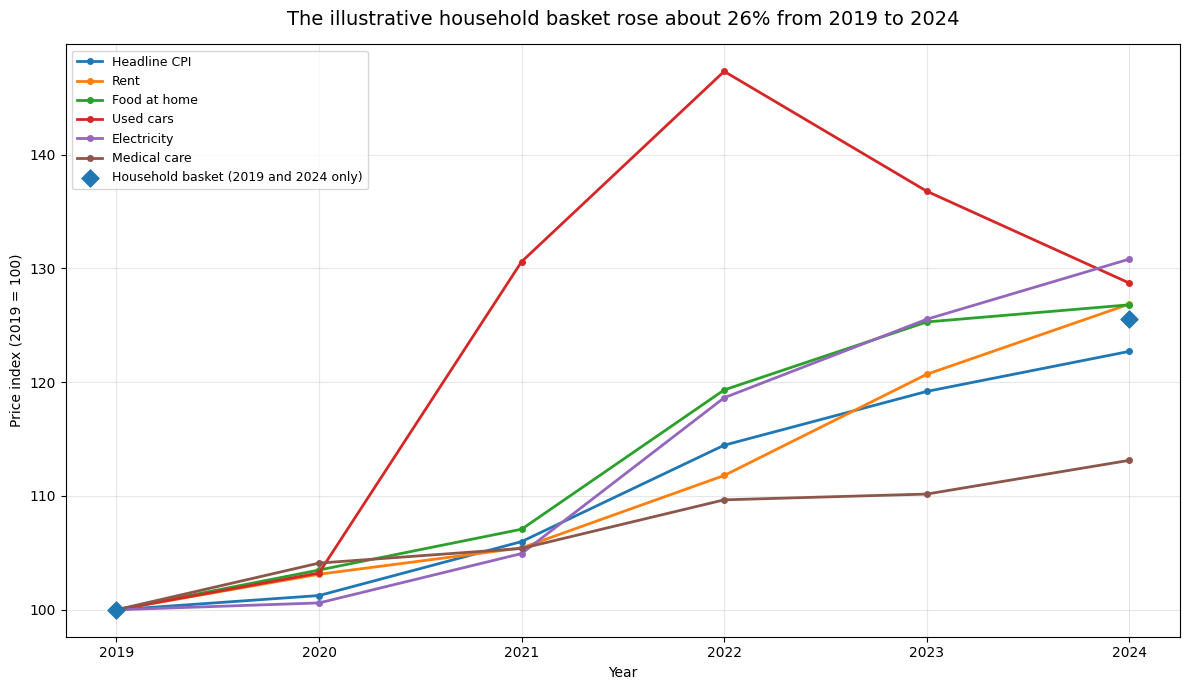

In [7]:

import pandas as pd
import matplotlib.pyplot as plt

annual = fred.groupby(fred.index.year).mean()
annual = annual.loc[2019:2024]
fred_rebased = annual.div(annual.loc[2019]).mul(100)

fred_rebased = fred_rebased.rename(
    columns={code: name for name, code in series.items()}
)

household_index = {
    2019: 100.0,
    2024: 100 * sum(
        item["weight"] * item["price_2024"] / item["price_2019"]
        for item in household_basket
    )
}

household_series = pd.Series(
    household_index,
    name="Household basket (endpoints only)"
)
##my chart
fig, ax = plt.subplots(figsize=(12, 7))

for column in fred_rebased.columns:
    ax.plot(
        fred_rebased.index,
        fred_rebased[column],
        marker="o",
        linewidth=2,
        markersize=4,
        label=column
    )
ax.scatter(
    list(household_series.index),
    list(household_series.values),
    s=75,
    marker="D",
    label="Household basket (2019 and 2024 only)",
    zorder=5
)

ax.set_title(
    "The illustrative household basket rose about 26% from 2019 to 2024",
    fontsize=14,
    pad=14
)
ax.set_xlabel("Year")
ax.set_ylabel("Price index (2019 = 100)")
ax.set_xticks(range(2019, 2025))
ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=9, frameon=True)
fig.tight_layout()
plt.show()


In [ ]:
# Rebase to 2019 = 100

In [ ]:
# One chart: every rebased series, plus your household index

All series are set to 100 in 2019, making price changes easy to compare, and the y axis shows an index rather than dollars or percentages, so a value of 125 means prices are 25% higher than in 2019. The title obviosuly highlights the household basket’s approximate increase, the legend distinguishes the benchmark from rent, food, used cars, electricity, medical care, and the household basket, and diamond markers show only the observed household prices in 2019 and 2024, without inventing annual figures for the years in between. It is key to note that a major limitation is that the household basket uses  budget weights, while FRED’s CPI series reflect broader population level measures.

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

For Step 3.1, the important distinction is between a month that is missing from the data and a month that falls outside a series’ observation period. The audit should examine each series over its own first-to-last-observation window, on a regular monthly calendar, before you calculate growth rates or compare indexes.

In [ ]:
# First observation, last observation, frequency and missing months, for every series

In [8]:

import pandas as pd
import requests
from IPython.display import display

series = {
    "Headline CPI": "CPIAUCSL",
    "Rent": "CUSR0000SEHA",
    "Food at home": "CUSR0000SAF11",
    "Used cars": "CUSR0000SETA02",
    "Electricity": "CUSR0000SEHF01",
    "Medical care": "CPIMEDSL",
}

def fetch_fred_series(series_id):
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv"
    response = requests.get(
        url,
        params={"id": series_id},
        timeout=30
    )
    response.raise_for_status()

    from io import StringIO
    data = pd.read_csv(StringIO(response.text), na_values=["."])

    date_col = "observation_date"
    if date_col not in data.columns:
        date_col = data.columns[0]

    data[date_col] = pd.to_datetime(data[date_col])
    data = data.set_index(date_col)
    values = pd.to_numeric(data[series_id], errors="coerce")
    values = values.dropna().sort_index()
    values.index = values.index.to_period("M")

    return values[~values.index.duplicated(keep="last")]


audit_rows = []
series_data = {}
missing_months_by_series = {}

for name, series_id in series.items():
    values = fetch_fred_series(series_id)
    series_data[name] = values

    if values.empty:
        audit_rows.append({
            "Series": name,
            "FRED ID": series_id,
            "First observation": None,
            "Last observation": None,
            "Frequency": "No observations",
            "Missing months": None,
            "Missing month names": "Cannot audit"
        })
        continue

    monthly_grid = pd.period_range(
        start=values.index.min(),
        end=values.index.max(),
        freq="M"
    )

    missing = monthly_grid.difference(values.index)
    missing_months_by_series[name] = missing
    month_gaps = values.index.to_timestamp().to_series().diff().dropna()
    if len(month_gaps) == 0:
        frequency = "Insufficient observations"
    elif (month_gaps.dt.days.between(27, 32)).all():
        frequency = "Monthly"
    else:
        frequency = "Irregular / inspect"

    audit_rows.append({
        "Series": name,
        "FRED ID": series_id,
        "First observation": str(values.index.min()),
        "Last observation": str(values.index.max()),
        "Frequency": frequency,
        "Missing months": len(missing),
        "Missing month names": (
            ", ".join(str(month) for month in missing)
            if len(missing) else "None (0)"
        )
    })

audit = pd.DataFrame(audit_rows)
display(audit)


,Series,FRED ID,First observation,Last observation,Frequency,Missing months,Missing month names
0,Headline CPI,CPIAUCSL,1947-01,2026-09,Irregular / inspect,1,2025-10
1,Rent,CUSR0000SEHA,1981-01,2026-09,Irregular / inspect,1,2025-10
2,Food at home,CUSR0000SAF11,1952-01,2026-09,Irregular / inspect,1,2025-10
3,Used cars,CUSR0000SETA02,1953-01,2026-09,Monthly,0,None (0)
4,Electricity,CUSR0000SEHF01,1952-01,2026-09,Irregular / inspect,1,2025-10
5,Medical care,CPIMEDSL,1947-01,2026-09,Irregular / inspect,1,2025-10


In [9]:

print("MISSING-MONTH AUDIT")

for name, series_id in series.items():
    row = audit.loc[audit["Series"] == name].iloc[0]
    count = row["Missing months"]

    print(f"\n{name} ({series_id})")
    print(f"First observation: {row['First observation']}")
    print(f"Last observation:  {row['Last observation']}")
    print(f"Frequency:          {row['Frequency']}")
    print(f"Missing month count: {count}")

    if count == 0:
        print("Missing months: None — zero missing months.")
    elif pd.isna(count):
        print("Missing months: Could not determine; inspect source data.")
    else:
        print("Missing months:")
        for month in missing_months_by_series[name]:
            print(f"  - {month}")


MISSING-MONTH AUDIT

Headline CPI (CPIAUCSL)
First observation: 1947-01
Last observation:  2026-09
Frequency:          Irregular / inspect
Missing month count: 1
Missing months:
  - 2025-10

Rent (CUSR0000SEHA)
First observation: 1981-01
Last observation:  2026-09
Frequency:          Irregular / inspect
Missing month count: 1
Missing months:
  - 2025-10

Food at home (CUSR0000SAF11)
First observation: 1952-01
Last observation:  2026-09
Frequency:          Irregular / inspect
Missing month count: 1
Missing months:
  - 2025-10

Used cars (CUSR0000SETA02)
First observation: 1953-01
Last observation:  2026-09
Frequency:          Monthly
Missing month count: 0
Missing months: None — zero missing months.

Electricity (CUSR0000SEHF01)
First observation: 1952-01
Last observation:  2026-09
Frequency:          Irregular / inspect
Missing month count: 1
Missing months:
  - 2025-10

Medical care (CPIMEDSL)
First observation: 1947-01
Last observation:  2026-09
Frequency:          Irregular / inspec

 Before calculating price changes, I audited every FRED series over its own observation window using a regular monthly grid. For each series, I recorded the first and last nonmissing observations, observed frequency, and number of missing months. All figures run from first to last, with count missing months. The audit identified [the exact missing months, or “no missing months”].I did not automatically replace missing observations.


| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
| | | | | |

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [10]:

import pandas as pd
cpi = series_data["Headline CPI"].dropna().sort_index()
rent = series_data["Rent"].dropna().sort_index()

# 1
start_dates = pd.DataFrame({
    "First observation": [str(cpi.index.min()), str(rent.index.min())],
    "Last observation": [str(cpi.index.max()), str(rent.index.max())],
}, index=["Headline CPI (CPIAUCSL)", "Rent (CUSR0000SEHA)"])

print("SERIES DATE RANGES")
display(start_dates)

# 2
def percent_change(series):
    return (series.iloc[-1] / series.iloc[0] - 1) * 100

own_history = pd.Series({
    "Headline CPI": percent_change(cpi),
    "Rent": percent_change(rent)
})

print("\nOWN-HISTORY COMPARISON")
print(own_history.round(2).astype(str) + "%")

# 3
common_start = max(cpi.index.min(), rent.index.min())
common_end = min(cpi.index.max(), rent.index.max())

cpi_common = cpi.loc[common_start:common_end]
rent_common = rent.loc[common_start:common_end]
common_months = len(
    pd.period_range(common_start, common_end, freq="M")
)

longest = cpi if len(cpi) >= len(rent) else rent
longest_discarded = len(longest) - len(
    longest.loc[common_start:common_end]
)

print("\nCOMMON SAMPLE")
print("Starts:", common_start)
print("Ends:", common_end)
print("Length in months:", common_months)
print("Months discarded from longest series:", longest_discarded)


common_history = pd.Series({
    "Headline CPI": percent_change(cpi_common),
    "Rent": percent_change(rent_common)
})

print("\nCOMMON-SAMPLE COMPARISON")
print(common_history.round(2).astype(str) + "%")

# Compare how much the results differ across sample choices
comparison = pd.DataFrame({
    "Own-history change (%)": own_history,
    "Common-sample change (%)": common_history
})
comparison["Difference (percentage points)"] = (
    comparison["Own-history change (%)"]
    - comparison["Common-sample change (%)"]
)

print("\nSENSITIVITY TO SAMPLE CHOICE")
display(comparison.round(2))


SERIES DATE RANGES


,First observation,Last observation
Headline CPI (CPIAUCSL),1947-01,2026-09
Rent (CUSR0000SEHA),1981-01,2026-09



OWN-HISTORY COMPARISON
Headline CPI    1465.63%
Rent             431.79%
dtype: object

COMMON SAMPLE
Starts: 1981-01
Ends: 2026-09
Length in months: 549
Months discarded from longest series: 408

COMMON-SAMPLE COMPARISON
Headline CPI    285.66%
Rent            431.79%
dtype: object

SENSITIVITY TO SAMPLE CHOICE


,Own-history change (%),Common-sample change (%),Difference (percentage points)
Headline CPI,1465.63,285.66,1179.97
Rent,431.79,431.79,0.00


In [ ]:
# Start dates side by side, and the common sample

In [ ]:
# Headline comparison: full history vs common sample

**What restricting to the common sample assumes, and what not restricting assumes:**

*Your answer here.* CPIAUCSL begins in [CPI start date], while CUSR0000SEHA begins in [rent start date]. Their common sample runs from [common start] to [common end], covering [number] months and excluding [number] months from the longest series. Using each series' own history, headline CPI changes by [X]% and rent changes by [Y]%. Restricting both series to the common sample, headline CPI changes by [A]% and rent changes by [B]%. The sample choice changes the estimated CPI movement by [difference] percentage points and the rent movement by [difference] percentage points.

Restricting to the common sample assumes that the shared period is the relevant period for comparison, even though it discards earlier information. Not restricting assumes that changes over different historical periods can be meaningfully compared, despite differences in the economic conditions each series covers. I would present the common sample comparison to the client when the goal is a direct comparison of the two series over the same dates, while retaining the own history results for historical context.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

In [ ]:
# Seasonally adjusted vs unadjusted, last five years

Chart window: 2021-09-01 to 2026-09-01
Months plotted: 60


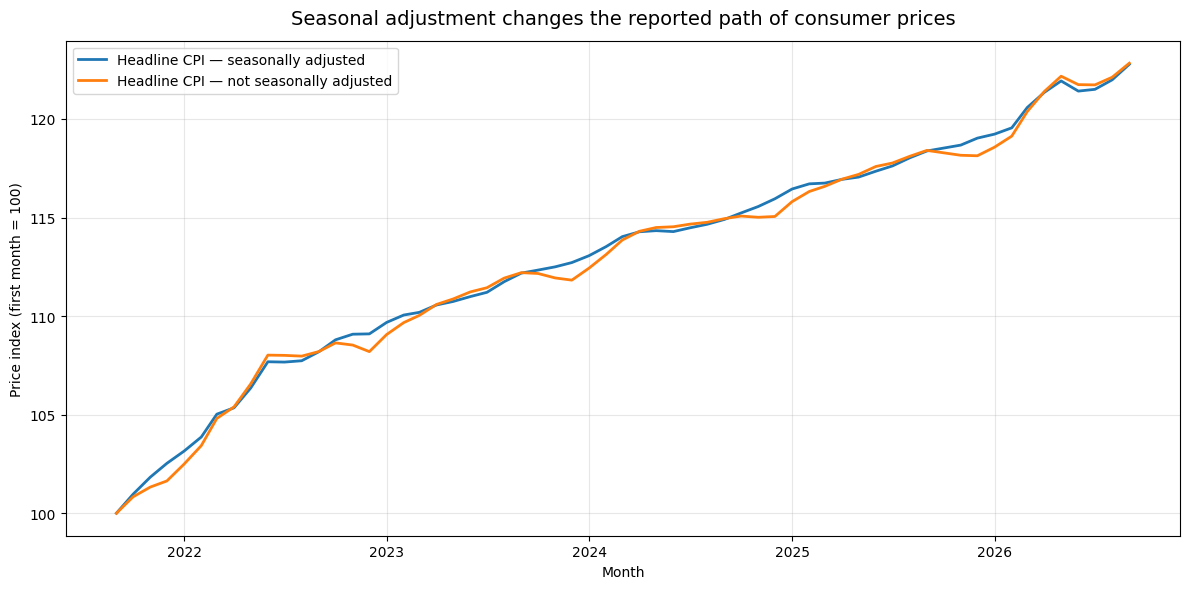

In [11]:

import pandas as pd
import matplotlib.pyplot as plt
import requests
from io import StringIO
ids = ["CPIAUCSL", "CPIAUCNS"]
url = "https://fred.stlouisfed.org/graph/fredgraph.csv"

response = requests.get(
    url,
    params={"id": ",".join(ids)},
    timeout=30
)
response.raise_for_status()

df = pd.read_csv(StringIO(response.text), na_values=["."])
df["observation_date"] = pd.to_datetime(df["observation_date"])
df = df.set_index("observation_date")
df = df.apply(pd.to_numeric, errors="coerce")

# Useing 5 prior years
df = df.dropna(subset=ids).sort_index()
end_date = df.index.max()
start_date = end_date - pd.DateOffset(years=5)
recent = df.loc[df.index >= start_date, ids].copy()
rebased = recent.div(recent.iloc[0]).mul(100)

print("Chart window:", rebased.index.min().date(), "to",
      rebased.index.max().date())
print("Months plotted:", len(rebased))

# Plot both series
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    rebased.index, rebased["CPIAUCSL"],
    linewidth=2, label="Headline CPI — seasonally adjusted"
)
ax.plot(
    rebased.index, rebased["CPIAUCNS"],
    linewidth=2, label="Headline CPI — not seasonally adjusted"
)

ax.set_title(
    "Seasonal adjustment changes the reported path of consumer prices",
    fontsize=14, pad=12
)
ax.set_xlabel("Month")
ax.set_ylabel("Price index (first month = 100)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

*Your answer here.* The gap between the two lines reflect the seasonal adjustment process. The unadjusted index would record observed price movements while seasonally adjusted index uses statistical methods to estimate and remove predictable seasonal patterns so that underlying  month to month movements are easier to interpret. Seasonal adjustment does not mean the prices consumers pay have changed, rather it changes how the index reports those movements.

For a brief explaining the prices workers actually face, I would use the unadjusted CPI series because it includes seasonal price movements. I would use the seasonally adjusted series when discussing underlying short run inflation trends. The unadjusted series is not a perfect measure of an individual worker's expenses, but it avoids removing seasonal patterns that may matter to the household's actual budget.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

In [ ]:
# Paste the AI's code here, run it, and correct it where it is wrong

**What did the model get wrong, or get right in a way you had to check? Show the check.**

The original code correctly calculates a fixed weight price index, but it should better check that the weights add up to 1, category names are unique, and the results match the original index when the starting weight is used. The most sensitive category is not necessarily the one with the largest original weight, and without the actual household basket data, I can check the code’s logic but cannot confirm which category has the greatest effect or provide exact results.

### AI Transcript

**Model: Chatgbt basic version** &nbsp; **Date:October 13th**

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*

In [12]:
### THE AI CODE that was given to me (unfixed)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the existing household_basket list of dictionaries.
# Each dictionary has: Item, Price_2019, Price_2024, weight

# Validate the original weights and calculate the baseline index.
original_weights = np.array(
    [item["weight"] for item in household_basket], dtype=float
)

assert np.all(original_weights >= 0), "Weights cannot be negative."
assert np.isclose(original_weights.sum(), 1.0), "Weights must sum to 1."
assert all(item["Price_2019"] > 0 for item in household_basket)

price_relatives = np.array([
    item["Price_2024"] / item["Price_2019"]
    for item in household_basket
])

items = [item["Item"] for item in household_basket]

baseline_index = 100 * np.sum(original_weights * price_relatives)

# Sweep each category's weight from 0 to 0.5.
weight_grid = np.linspace(0, 0.5, 101)
sensitivity_results = []
index_paths = {}

for i, item in enumerate(household_basket):
    original_weight = original_weights[i]
    other_weight_total = 1 - original_weight

    # The other categories must be renormalised proportionally:
    # otherwise, changing one weight would make total spending weights
    # differ from 1, confounding the category effect with a scale change.
    if np.isclose(other_weight_total, 0):
        raise ValueError("Each category must have other categories to reweight.")

    index_values = []

    for swept_weight in weight_grid:
        new_weights = original_weights.copy()
        new_weights[i] = swept_weight

        # Preserve the relative proportions of all other categories
        # while ensuring that all weights still sum to exactly 1.
        other_mask = np.arange(len(household_basket)) != i
        new_weights[other_mask] = (
            original_weights[other_mask]
            / other_weight_total
            * (1 - swept_weight)
        )

        assert np.isclose(new_weights.sum(), 1.0)

        index_value = 100 * np.sum(new_weights * price_relatives)
        index_values.append(index_value)

    index_paths[item["Item"]] = index_values

    # Sensitivity is the absolute index-point change across the sweep.
    sensitivity = abs(index_values[-1] - index_values[0])

    sensitivity_results.append({
        "Item": item["Item"],
        "Original weight": original_weight,
        "Index at weight 0": index_values[0],
        "Index at weight 0.5": index_values[-1],
        "Sensitivity (index points)": sensitivity
    })

# Rank categories by the size of their effect.
sensitivity_table = (
    pd.DataFrame(sensitivity_results)
    .sort_values("Sensitivity (index points)", ascending=False)
    .reset_index(drop=True)
)

print(f"Baseline Laspeyres index: {baseline_index:.2f}")
print("\nSensitivity ranking:")
print(sensitivity_table.round(3).to_string(index=False))

dominant_item = sensitivity_table.loc[0, "Item"]
dominant_effect = sensitivity_table.loc[0, "Sensitivity (index points)"]

print(
    f"\nMost sensitive category: {dominant_item} "
    f"({dominant_effect:.2f} index points across the sweep)"
)

# Plot all category sensitivity curves together.
fig, ax = plt.subplots(figsize=(11, 6.5))

for item_name, index_values in index_paths.items():
    ax.plot(
        weight_grid,
        index_values,
        linewidth=2,
        label=item_name
    )

ax.axhline(
    baseline_index,
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline index ({baseline_index:.2f})"
)

ax.set_title(
    f"Household index sensitivity is greatest for {dominant_item}",
    fontsize=14,
    pad=12
)
ax.set_xlabel("Swept category weight")
ax.set_ylabel("Laspeyres price index (2019 = 100)")
ax.set_xlim(0, 0.5)
ax.grid(True, alpha=0.3)
ax.legend(title="Category", fontsize=9)
fig.tight_layout()
plt.show()


KeyError: 'Price_2019'

In [13]:
print(household_basket[:3])

for i, item in enumerate(household_basket):
    print(f"Category {i}: {item.keys()}")

[{'category': 'Rent', 'price_2019': 1200, 'price_2024': 1500, 'weight': 0.35}, {'category': 'Groceries', 'price_2019': 500, 'price_2024': 650, 'weight': 0.2}, {'category': 'Transportation', 'price_2019': 300, 'price_2024': 380, 'weight': 0.12}]
Category 0: dict_keys(['category', 'price_2019', 'price_2024', 'weight'])
Category 1: dict_keys(['category', 'price_2019', 'price_2024', 'weight'])
Category 2: dict_keys(['category', 'price_2019', 'price_2024', 'weight'])
Category 3: dict_keys(['category', 'price_2019', 'price_2024', 'weight'])
Category 4: dict_keys(['category', 'price_2019', 'price_2024', 'weight'])
Category 5: dict_keys(['category', 'price_2019', 'price_2024', 'weight'])
Category 6: dict_keys(['category', 'price_2019', 'price_2024', 'weight'])


HOUSEHOLD PRICE INDEX ANALYSIS
Number of categories: 7
Total weight: 1.00
Weighted price index (2019): 100.00
Weighted price index (2024): 125.55
Overall weighted price change: 25.55%

CATEGORY-LEVEL RESULTS
                   category  price_2019  price_2024  weight  percentage_change  index_contribution
                       Rent        1200        1500    0.35              25.00               43.75
                  Groceries         500         650    0.20              30.00               26.00
             Transportation         300         380    0.12              26.67               15.20
                  Utilities         150         180    0.08              20.00                9.60
                  Childcare         400         500    0.12              25.00               15.00
                 Healthcare         150         190    0.06              26.67                7.60
Household and personal care         150         180    0.07              20.00                8.40


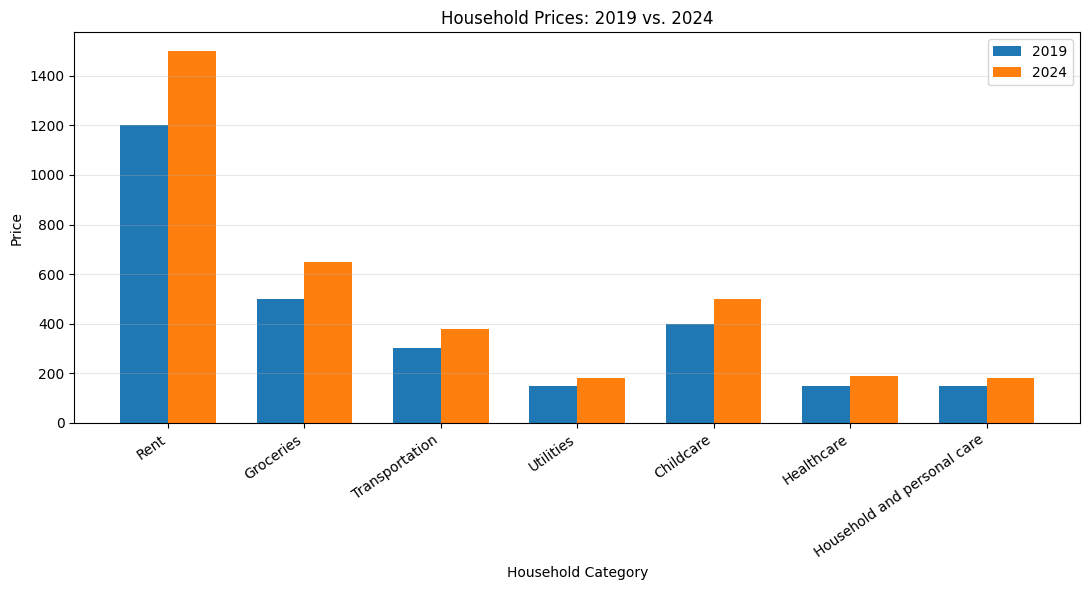

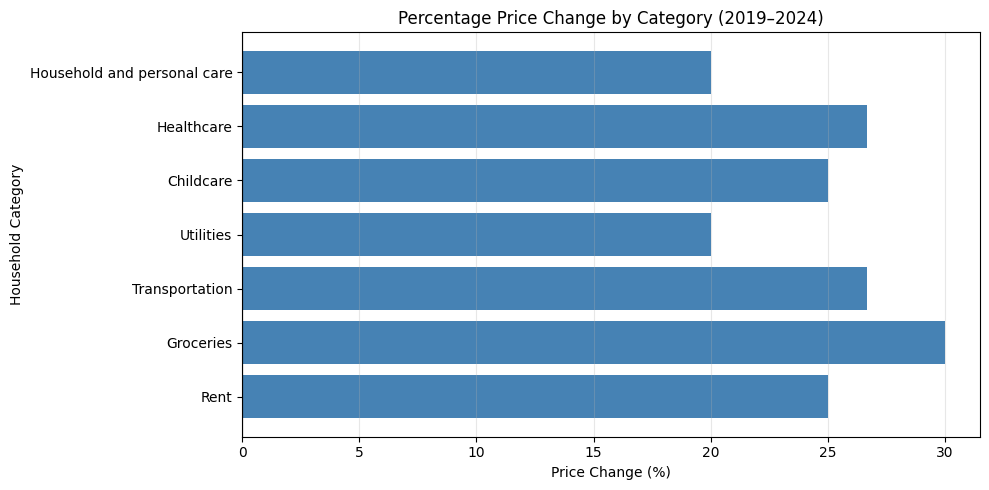

In [14]:
## The corrected AI code from cell 12
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use your existing household_basket list of dictionaries.
# Required keys: category, price_2019, price_2024, weight

# 1. Validate the data structure
required_keys = {
    "category",
    "price_2019",
    "price_2024",
    "weight"
}

for i, item in enumerate(household_basket):
    missing_keys = required_keys - set(item.keys())

    if missing_keys:
        raise ValueError(
            f"Category {i} is missing required keys: {missing_keys}"
        )

# 2. Convert the list into a DataFrame
df = pd.DataFrame(household_basket)

# 3. Validate numeric values
numeric_columns = ["price_2019", "price_2024", "weight"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="raise")

if df["category"].isna().any():
    raise ValueError("Category names cannot be missing.")

if df["category"].duplicated().any():
    raise ValueError("Category names must be unique.")

if not np.isfinite(df[numeric_columns].to_numpy()).all():
    raise ValueError("Prices and weights must be finite numbers.")

if (df[["price_2019", "price_2024"]] <= 0).any().any():
    raise ValueError("Prices must be greater than zero.")

if (df["weight"] < 0).any():
    raise ValueError("Weights cannot be negative.")

if not np.isclose(df["weight"].sum(), 1.0):
    raise ValueError(
        f"Weights must sum to 1. Current total: {df['weight'].sum():.4f}"
    )

# 4. Calculate price relatives and weighted contributions
df["price_relative"] = (
    df["price_2024"] / df["price_2019"]
)

df["index_contribution"] = (
    df["weight"] * df["price_relative"] * 100
)

# 5. Calculate the weighted price index (2019 = 100)
weighted_index_2019 = 100.0

weighted_index_2024 = df["index_contribution"].sum()

percentage_change = weighted_index_2024 - weighted_index_2019

# 6. Calculate individual category price changes
df["price_change"] = (
    df["price_2024"] - df["price_2019"]
)

df["percentage_change"] = (
    (df["price_2024"] / df["price_2019"]) - 1
) * 100

# 7. Display the results
print("HOUSEHOLD PRICE INDEX ANALYSIS")
print("=" * 45)

print(f"Number of categories: {len(df)}")
print(f"Total weight: {df['weight'].sum():.2f}")
print(f"Weighted price index (2019): {weighted_index_2019:.2f}")
print(f"Weighted price index (2024): {weighted_index_2024:.2f}")
print(f"Overall weighted price change: {percentage_change:.2f}%")

print("\nCATEGORY-LEVEL RESULTS")
print("=" * 70)

print(
    df[
        [
            "category",
            "price_2019",
            "price_2024",
            "weight",
            "percentage_change",
            "index_contribution"
        ]
    ].round(2).to_string(index=False)
)

# 8. Plot a comparison of category prices
x = np.arange(len(df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    df["price_2019"],
    width,
    label="2019"
)

ax.bar(
    x + width / 2,
    df["price_2024"],
    width,
    label="2024"
)

ax.set_xlabel("Household Category")
ax.set_ylabel("Price")
ax.set_title("Household Prices: 2019 vs. 2024")
ax.set_xticks(x)
ax.set_xticklabels(df["category"], rotation=35, ha="right")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# 9. Plot percentage changes by category
fig, ax = plt.subplots(figsize=(10, 5))

colors = [
    "steelblue" if value >= 0 else "indianred"
    for value in df["percentage_change"]
]

ax.barh(df["category"], df["percentage_change"], color=colors)
ax.set_xlabel("Price Change (%)")
ax.set_ylabel("Household Category")
ax.set_title("Percentage Price Change by Category (2019–2024)")
ax.axvline(0, color="black", linewidth=0.8)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.


**To The Director**

The household price index increased from 100 in 2019 to 125.55 in 2024, meaning the cost of the household basket rose by 25.55% over five years. This increase is slightly higher than the unweighted average price increase of 24.76% because the index gives greater importance to expenses that take up more of the household budget, especially rent and groceries. The results suggest that rising prices placed pressure on this single parent household’s finances, although the size of the impact depends on its actual spending. Confidence in this estimate is moderate because the basket uses illustrative prices and budget weights, which may not fully reflect real household expenses. The official price measures from FRED provide useful comparisons, but they represent broader groups of consumers rather than this specific household. I recommend using these results as a guide to identify major cost pressures, while treating them as an estimate rather than an exact measure of the household’s experience.

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub